# IC50 calculation and plot (one or more data sets)

This notebook fits a dose-response curve to your data and calculates the IC50. Your spreadsheet needs a column called **conc** (the inhibitor concentration), plus **one column for each set of rate measurements** (call them whatever you like, e.g. "Oxalate", "Control"). Each rate column is fitted separately and all the curves are drawn on the same graph.

In [1]:
# 0. Import all the Python libraries needed for this calculation

import micropip
await micropip.install('openpyxl')   # lets Python read Excel files in this environment

import os
import pandas as pd
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt

The rest of these code cells calculate and plot your IC50 data. Firstly we need to load the data, and define the variables based on that data which we will use in the rest of the calculations. Every column other than `conc` is treated as a separate data set.

In [2]:
# 1. Load Data
file_path = 'IC50_Data_Multi.xlsx'

if not os.path.exists(file_path):
    raise FileNotFoundError(f"The file '{file_path}' was not found. Please check that the 'data' folder contains 'Oxalate_IC50.xlsx'.")

df = pd.read_excel(file_path)
df = df.dropna(axis=1, how='all')    # remove any completely empty columns

if 'conc' not in df.columns:
    raise KeyError("The spreadsheet must contain a column called 'conc'. Please check your column names.")

df = df.dropna(subset=['conc']).sort_values(by='conc').reset_index(drop=True)

# Every column other than 'conc' is a separate set of rate measurements
rate_columns = [c for c in df.columns if c != 'conc']
print(f"Found {len(rate_columns)} data set(s): {rate_columns}")

# Define X_min_plot as the smallest non-zero concentration (avoids problems with log(0))
X_all = df['conc'].values
X_non_zero = X_all[X_all > 0]
if len(X_non_zero) == 0:
    raise ValueError("Concentration data contains no positive values, so a log-scale plot is not possible.")

X_min_plot = X_non_zero.min()
X_max_plot = X_all.max()

Found 6 data set(s): ['GPR109', 'Asc oligomerziatoin by biacore', 'GPR109_cAMP', 'ASC oligomerization Western', 'Caspase-1 activity (LPS)', 'IL-1 secretion']


Next, we need to define the "equation" that Python is going to use to calculate a best-fit line for our data. The equation used is called a four-parameter logistic fit.

The equation used to fit your dose-response curve is:

$$
Y = D + \frac{A - D}{1 + \left(\frac{X}{IC_{50}}\right)^B}
$$

**Where the parameters represent:**

| Parameter | Meaning | Corresponds to |
| :---: | :--- | :--- |
| **Y** | Measured Enzyme Activity/Rate | Output |
| **X** | Inhibitor Concentration | Input |
| **A** | The top plateau of the sigmoidal curve | Fitted Max Rate |
| **D** | The bottom plateau of the sigmoidal curve | Fitted Min Rate |
| $\mathbf{IC_{50}}$ | Inflection Point **(called C in the python code)** | The concentration at half-maximal effect. |
| **B** | Hill Slope | Steepness of the curve. |

In [3]:
# 2. Define the Four-Parameter Logistic (4PL) Model
def four_param_logistic(X, A, B, C, D):
    """
    4PL sigmoidal function for inhibition curve fitting.
    A: Top, D: Bottom, C: IC50, B: Hill slope
    """
    return D + (A - D) / (1 + (X / C)**B)

Now we're going to estimate starting values for the parameters, based on the data we've given Python, and set the boundaries that the fitted values are allowed to lie between. Python then finds the set of parameters that best fits your experimental data. This is repeated for **each data set in turn**.

In [4]:
# 3. Fit the 4PL model to each data set
results = []          # one row of summary results per data set
fitted_params = {}    # best-fit parameters for each data set (used later for plotting)

for name in rate_columns:
    # Use only the rows where both the concentration and this data set's rate are present
    data = df[['conc', name]].dropna()
    X = data['conc'].values
    Y = data[name].values

    # The model has 4 parameters, so we need a reasonable number of points
    if len(X) < 5:
        print(f"Skipping '{name}': only {len(X)} data points (need at least 5).")
        continue

    # Initial guesses (p0)
    A_guess = Y.max()
    D_guess = Y.min()
    mid_point = (A_guess + D_guess) / 2.0
    idx = np.argmin(np.abs(Y - mid_point))
    C_guess = X[idx]
    if C_guess <= 0:
        C_guess = np.sqrt(X_min_plot * X_max_plot)
    B_guess = 1.0
    p0 = [A_guess, B_guess, C_guess, D_guess]

    # Bounds for the fitted values
    lower_bounds = [Y.min() * 0.5, 0.1, X_min_plot / 10.0, Y.min() * 0.9]
    upper_bounds = [Y.max() * 1.5, 10.0, X_max_plot * 10.0, Y.max() * 1.1]

    try:
        popt, pcov = curve_fit(four_param_logistic, X, Y, p0=p0, bounds=(lower_bounds, upper_bounds))
        A_fit, B_fit, IC50_fit, D_fit = popt

        # R-squared and standard error of the IC50
        residuals = Y - four_param_logistic(X, *popt)
        ss_res = np.sum(residuals**2)
        ss_tot = np.sum((Y - np.mean(Y))**2)
        r_squared = 1 - (ss_res / ss_tot)
        perr = np.sqrt(np.diag(pcov))

        results.append({'Data set': name,
                        'IC50': IC50_fit,
                        'IC50 std error': perr[2],
                        'R-squared': r_squared,
                        'Hill slope (B)': B_fit,
                        'Top (A)': A_fit,
                        'Bottom (D)': D_fit})
        fitted_params[name] = popt

    except (RuntimeError, ValueError):
        print(f"Error: Optimal parameters not found for '{name}'. This data set has been left out.")

print(f"\nSuccessfully fitted {len(results)} of {len(rate_columns)} data set(s).")


Successfully fitted 6 of 6 data set(s).


Assuming that has worked, saved somewhere in the guts of the computer are values for all the parameters of each data set. That's great, but we'd quite like to know what they are. The next block of code prints a results table, and saves it as a file.

In [5]:
# 4. Results table
if len(results) == 0:
    print("IC50 calculation failed for all data sets.")
else:
    results_df = pd.DataFrame(results)

    print("--- IC50 Calculation Results ---")
    print(results_df.to_string(index=False, float_format=lambda x: f"{x:.3g}"))

    # Save the table (the 'output_files' folder is created if it doesn't already exist)
    os.makedirs('output_files', exist_ok=True)
    results_df.to_csv('output_files/IC50_results.csv', index=False)
    print("\nResults table saved as 'output_files/IC50_results.csv'")

--- IC50 Calculation Results ---
                      Data set     IC50  IC50 std error  R-squared  Hill slope (B)  Top (A)  Bottom (D)
                        GPR109 9.25e-08        1.09e-08      0.997           0.977      101         0.9
Asc oligomerziatoin by biacore 9.57e-09        1.01e-09      0.999           0.951      102    2.19e-11
                   GPR109_cAMP 9.32e-08        7.72e-09      0.998           0.969     99.5        19.4
   ASC oligomerization Western 1.48e-08        1.15e-09      0.999            1.04     98.9     0.00353
      Caspase-1 activity (LPS) 1.99e-08        2.34e-09      0.998            1.02      101       0.222
                IL-1 secretion 3.18e-08        1.84e-09      0.999             1.1     97.4       0.414

Results table saved as 'output_files/IC50_results.csv'


Finally, we want to see each line of best fit (i.e. the curve that corresponds to the equation at each value of X) alongside the experimental points. All the data sets are drawn on one graph, each in its own colour, with dashed lines marking the IC50. The plot is saved in the **output_files** folder.

**Before you finish the session, download your results:** in the file browser on the left, open the `output_files` folder, right-click each file and choose **Download**.

<ipython-input-6-62d2e2a25eb8>:40: MatplotlibDeprecationWarning: The width parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(width) instead.
  plt.savefig('output_files/IC50_Dose_Response_Fit.png')
<ipython-input-6-62d2e2a25eb8>:40: MatplotlibDeprecationWarning: The height parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(height) instead.
  plt.savefig('output_files/IC50_Dose_Response_Fit.png')
<ipython-input-6-62d2e2a25eb8>:40: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig('output_files/IC50_Dose_Response_Fit.png')
<ipython-input-6-62d2e2a25eb8>:40: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig('output_files/IC50_Dose_Response_Fit.png')


Plot saved as 'output_files/IC50_Dose_Response_Fit.png'


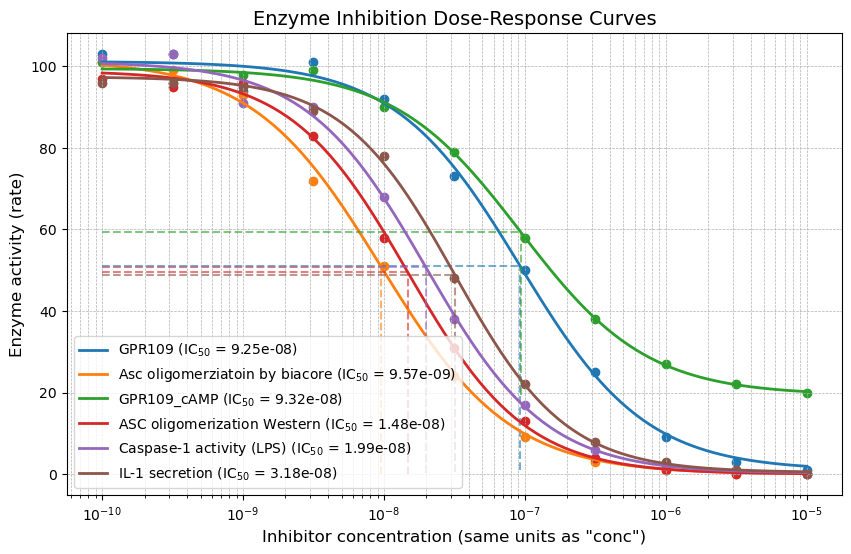

In [6]:
# 5. Plot all the data sets on one graph
if len(results) > 0:
    colours = plt.cm.tab10.colors          # a set of 10 distinct colours

    # Smooth curve x-values (log-spaced, from the smallest non-zero concentration up)
    X_fit = np.logspace(np.log10(X_min_plot), np.log10(X_max_plot), 100)

    plt.figure(figsize=(10, 6))

    for i, row in results_df.iterrows():
        name = row['Data set']
        popt = fitted_params[name]
        IC50_fit = row['IC50']
        D_fit = popt[3]
        colour = colours[i % len(colours)]

        # Experimental data points for this data set
        data = df[['conc', name]].dropna()
        plt.scatter(data['conc'], data[name], color=colour, marker='o')

        # Line of best fit for this data set
        Y_fit = four_param_logistic(X_fit, *popt)
        plt.plot(X_fit, Y_fit, '-', color=colour, linewidth=2,
                 label=rf"{name} ($\mathrm{{IC}}_{{50}}$ = {IC50_fit:.2e})")

        # Dashed lines marking the IC50 point
        y_IC50 = four_param_logistic(IC50_fit, *popt)
        plt.hlines(y=y_IC50, xmin=X_min_plot, xmax=IC50_fit, color=colour, linestyle='--', alpha=0.6)
        plt.vlines(x=IC50_fit, ymin=D_fit, ymax=y_IC50, color=colour, linestyle='--', alpha=0.6)

    plt.xscale('log')
    plt.xlabel('Inhibitor concentration (same units as "conc")', fontsize=12)
    plt.ylabel('Enzyme activity (rate)', fontsize=12)
    plt.title('Enzyme Inhibition Dose-Response Curves', fontsize=14)
    plt.legend(fontsize=10)
    plt.grid(True, which="both", ls="--", linewidth=0.5)

    # Save the plot, then show it
    os.makedirs('output_files', exist_ok=True)
    plt.savefig('output_files/IC50_Dose_Response_Fit.png')
    print("Plot saved as 'output_files/IC50_Dose_Response_Fit.png'")
    plt.show()
else:
    print("Nothing to plot: the IC50 calculation failed for all data sets.")

# --- End of the IC50 Calculation Script ---